# **Codigo de prediccion de fallos en coolers**

Equipo: Glitch Girls

Con el fin de abordar el reto de predicción de fallas de Smart Coolers se emplea la metodología CRISP-DM.
**Metodología CRISP**
##Comprensión del negocio
Desde la perspectiva del negocio, el funcionamiento de los enfriadores resultan críticos en la ventas de Coca-Cola, en donde al fallar, se pierden oportunidades de venta.
El objetivo del proyecto es el desarrollo de un modelo de mantenimiento predictivo que sea capaz de anticipar las fallas empleando señales de sensores dentro de los equipos.
Esto con el fin de reducir fallas inesperadas, mejorar la eficiencia operativa, evitar la pérdida de ingresos y tiempo.

##Comprensión de los datos
A modo de entender los datos diponibles, detectar algunos patrones iniciales se hace una revisión de los datos entregados.

### Importacion de librerias

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score
import gdown

### Carga de datos usando gdown

Se cargaron los 4 conjuntos de datos sobre registros históricos

In [ ]:
#Enlaces a drive para el manejo seguro de los datos de forma inmediata
urls = {
    "warnings.csv": "https://drive.google.com/file/d/1XcIbvzNwknAXmALkIrDU-Qgw-aGP8jHV/view?usp=sharing",
    "sales.csv": "https://drive.google.com/file/d/1s23001Az_2-q2HIKWWuTKzcnqAv8jh_Z/view?usp=sharing",
    "coolers.csv": "https://drive.google.com/file/d/1fxH1JSaGKZZBy1ba3m8bi6dlejijsUKT/view?usp=sharing",
    "calendar.csv": "https://drive.google.com/file/d/19UUmBnd6ctP8wqjX-693O-16Fp6tpepN/view?usp=sharing"
}

for filename, url in urls.items():
    # Extraer el ID del archivo de la URL
    file_id = url.split("/d/")[1].split("/")[0]
    # Construir el enlace directo de descarga
    download_url = f"https://drive.google.com/uc?id={file_id}"
    # Descargar el archivo usando gdown
    gdown.download(download_url, filename, quiet=False)

warnings = pd.read_csv("warnings.csv")
sales = pd.read_csv("sales.csv")
coolers = pd.read_csv("coolers.csv")
calendar = pd.read_csv("calendar.csv")

Downloading...
From: https://drive.google.com/uc?id=1XcIbvzNwknAXmALkIrDU-Qgw-aGP8jHV
To: /content/warnings.csv
100%|██████████| 3.46k/3.46k [00:00<00:00, 6.85MB/s]
Downloading...
From: https://drive.google.com/uc?id=1s23001Az_2-q2HIKWWuTKzcnqAv8jh_Z
To: /content/sales.csv
100%|██████████| 29.8M/29.8M [00:00<00:00, 105MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1fxH1JSaGKZZBy1ba3m8bi6dlejijsUKT
To: /content/coolers.csv
100%|██████████| 40.5M/40.5M [00:00<00:00, 213MB/s]
Downloading...
From: https://drive.google.com/uc?id=19UUmBnd6ctP8wqjX-693O-16Fp6tpepN
To: /content/calendar.csv
100%|██████████| 20.1k/20.1k [00:00<00:00, 14.4MB/s]


### Preparacion Inicial de Datos

Se observa que en cada una de las bases de datos hay cantidades distintas de registros, para lo que se va a estudiar la distribución de estas

In [ ]:
print(sales.shape)
print(warnings.shape)
print(coolers.shape)
print(calendar.shape)

(204736, 4)
(53, 1)
(335216, 10)
(851, 3)


In [ ]:
print("Primeras 5 filas de 'warnings':")
print(warnings.head())
print("\nPrimeras 5 filas de 'sales':")
print(sales.head())
print("\nPrimeras 5 filas de 'coolers':")
print(coolers.head())
print("\nPrimeras 5 filas de 'calendar':")
print(calendar.head())

Primeras 5 filas de 'warnings':
                                           cooler_id
0  483fe5b436f370171a15a80520839049bd7c4b8416c28e...
1  51acd7bdf1c17f571df58541440547e2bf6e30e322cd1c...
2  b6edb73e7212f812ffe4b38eae69e06f9f2940d76238f4...
3  8d3260b5f7e49fff02b4743037a52406b19279d9cd0144...
4  75e325ac11632c676a299c5d28f3dca83bd628deb8b62f...

Primeras 5 filas de 'sales':
                                           cooler_id  \
0  42d9b14c937541b8f1287ce7251d1e29f1f8eb58dbcd7e...   
1  42d9b14c937541b8f1287ce7251d1e29f1f8eb58dbcd7e...   
2  42d9b14c937541b8f1287ce7251d1e29f1f8eb58dbcd7e...   
3  42d9b14c937541b8f1287ce7251d1e29f1f8eb58dbcd7e...   
4  42d9b14c937541b8f1287ce7251d1e29f1f8eb58dbcd7e...   

                                         customer_id  calmonth    amount  
0  e21b830bc395b5a355f68a698c55ad95474f929d8e2521...    202503   76.8887  
1  e21b830bc395b5a355f68a698c55ad95474f929d8e2521...    202412  131.0627  
2  e21b830bc395b5a355f68a698c55ad95474f929d8e2521...    20

In [ ]:
print("\nInformación general de 'warnings':")
warnings.info()

print("\nEstadísticas descriptivas de 'warnings':")
print(warnings.describe(include='all'))

print("\nValores nulos en 'warnings':")
print(warnings.isnull().sum())

# Contar solo un registro por cooler_id en warnings
print("\nConteo de registros únicos por cooler_id en 'warnings':")
print(warnings['cooler_id'].nunique())


print("\nInformación general de 'sales':")
sales.info()

print("\nEstadísticas descriptivas de 'sales':")
print(sales.describe(include='all'))

print("\nValores nulos en 'sales':")
print(sales.isnull().sum())

print("\nInformación general de 'coolers':")
coolers.info()

print("\nEstadísticas descriptivas de 'coolers':")
print(coolers.describe(include='all'))

print("\nValores nulos en 'coolers':")
print(coolers.isnull().sum())

print("\nInformación general de 'calendar':")
calendar.info()

print("\nEstadísticas descriptivas de 'calendar':")
print(calendar.describe(include='all'))

print("\nValores nulos en 'calendar':")
print(calendar.isnull().sum())


Información general de 'warnings':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   cooler_id  53 non-null     object
dtypes: object(1)
memory usage: 556.0+ bytes

Estadísticas descriptivas de 'warnings':
                                                cooler_id
count                                                  53
unique                                                 53
top     483fe5b436f370171a15a80520839049bd7c4b8416c28e...
freq                                                    1

Valores nulos en 'warnings':
cooler_id    0
dtype: int64

Conteo de registros únicos por cooler_id en 'warnings':
53

Información general de 'sales':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204736 entries, 0 to 204735
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   cooler_id    204

In [ ]:
print("\nValores nulos en cada base de datos:")
print("\nWarnings:")
print(warnings.isnull().sum())

print("\nSales:")
print(sales.isnull().sum())

print("\nCoolers:")
print(coolers.isnull().sum())

print("\nCalendar:")
print(calendar.isnull().sum())


Valores nulos en cada base de datos:

Warnings:
cooler_id    0
dtype: int64

Sales:
cooler_id      0
customer_id    0
calmonth       0
amount         0
dtype: int64

Coolers:
cooler_id          0
door_opens     20921
open_time         74
compressor     20584
power          20921
on_time         6913
min_voltage    27838
max_voltage    27838
temperature    20400
calday             0
dtype: int64

Calendar:
calday      0
calmonth    0
day         0
dtype: int64


In [ ]:
# Creacion de variable objetivo binaria (1:tuvo fallo, 0:no tuvo fallo)
coolers['has_warning'] = coolers['cooler_id'].isin(warnings['cooler_id']).astype(int)

# Conversion a formato datetime
coolers['calday'] = pd.to_datetime(coolers['calday'], format='%Y%m%d')
calendar['calday'] = pd.to_datetime(calendar['calday'], format='%Y%m%d')

# Unir datos de calendario con los del cooler para agregar día de la semana
coolers = coolers.merge(calendar, on="calday", how="left")

# Creamos una variable de mes en formato YYYYMM para poder unirlo con las ventas
coolers['calmonth'] = coolers['calday'].dt.to_period('M').astype(str).str.replace('-', '').astype(int)
sales['calmonth'] = sales['calmonth'].astype(int)

# Union datos de sensores y ventas
df = coolers.merge(sales, on=['cooler_id', 'calmonth'], how="left")
df['amount'] = df['amount'].fillna(0)  # Si no hubo ventas, se asume 0
df['day'] = df['day'].astype('category').cat.codes  # Codificamos el día como variable numérica

Para la visualización y entendimiento de la información lo más relevante es conocer el balance de la información y así poder determinar como hacer el manejo de los datos.

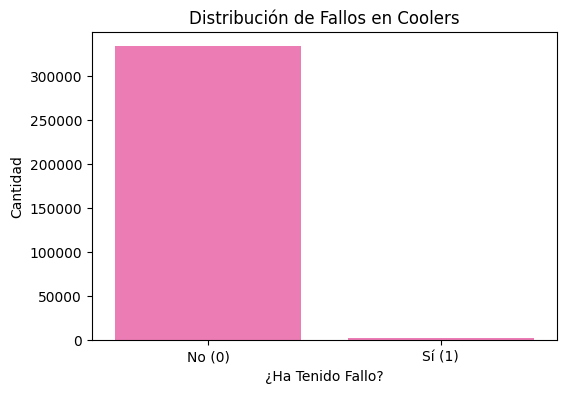

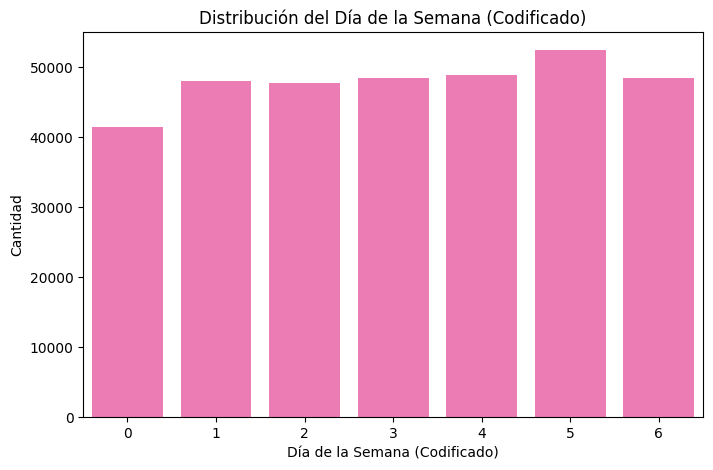

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribución de la variable objetivo
plt.figure(figsize=(6, 4))
sns.countplot(x='has_warning', data=df, color='hotpink')
plt.title('Distribución de Fallos en Coolers')
plt.xlabel('¿Ha Tenido Fallo?')
plt.ylabel('Cantidad')
plt.xticks([0, 1], ['No (0)', 'Sí (1)'])
plt.show()

#Otra métrica es
# Distribución del día de la semana (day) - después de la codificación
plt.figure(figsize=(8, 5))
sns.countplot(x='day', data=df, color='hotpink')
plt.title('Distribución del Día de la Semana (Codificado)')
plt.xlabel('Día de la Semana (Codificado)')
plt.ylabel('Cantidad')
plt.show()

Para entender el comportamiento de los coolers, se hizo el análisis de gráficos de uno sólo de estos que se extrajo de los ID que tienen warning.

En ese sentido, se grafica su comportamiento en cad área a lo largo del tiempo.

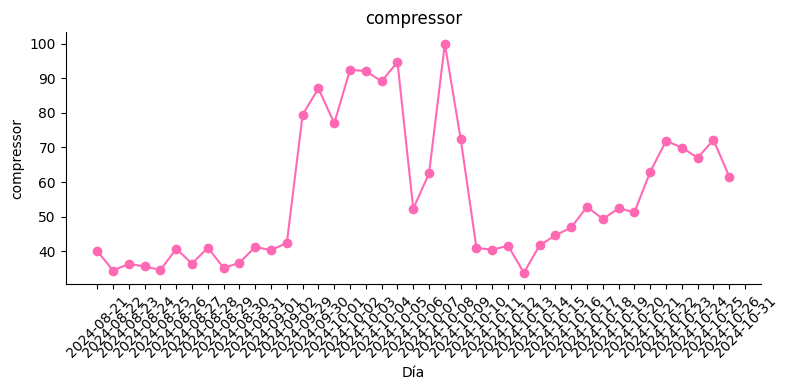

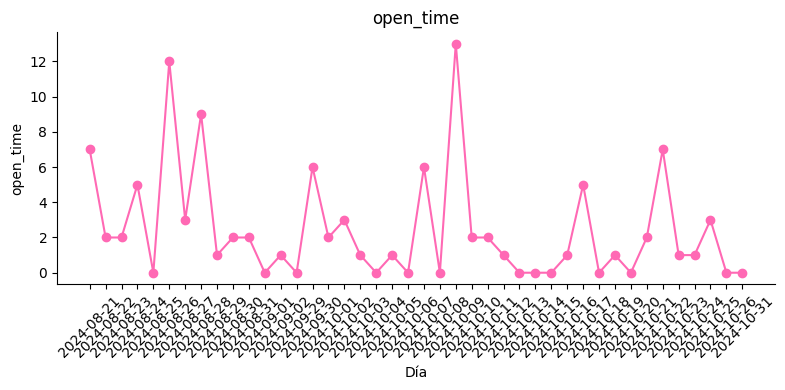

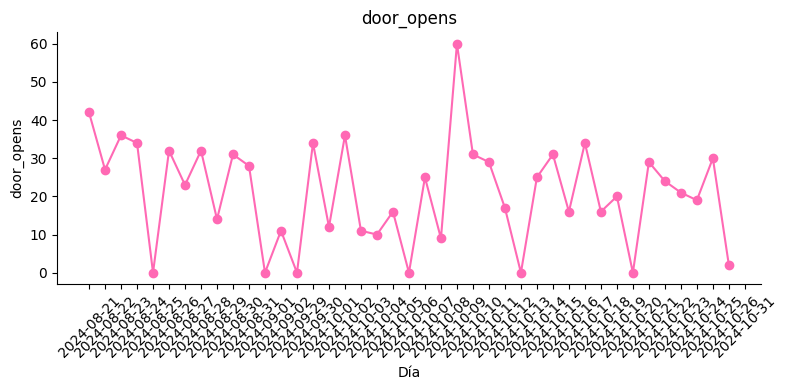

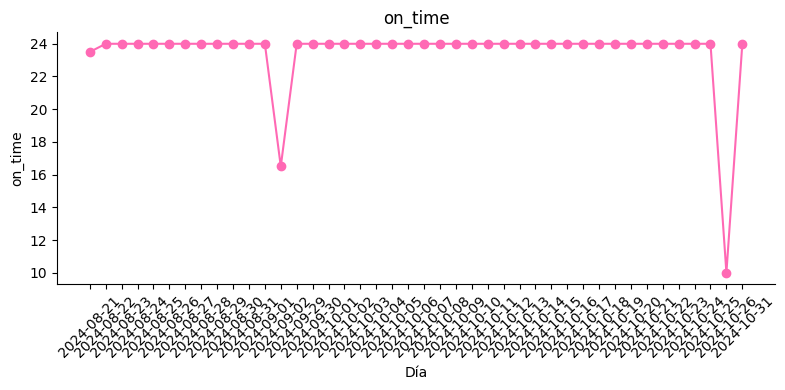

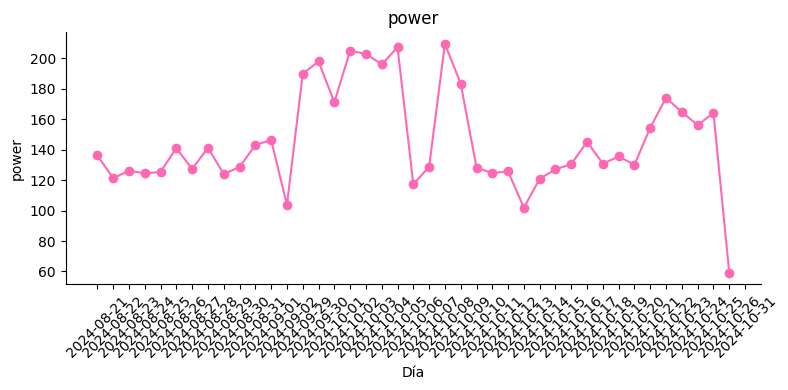

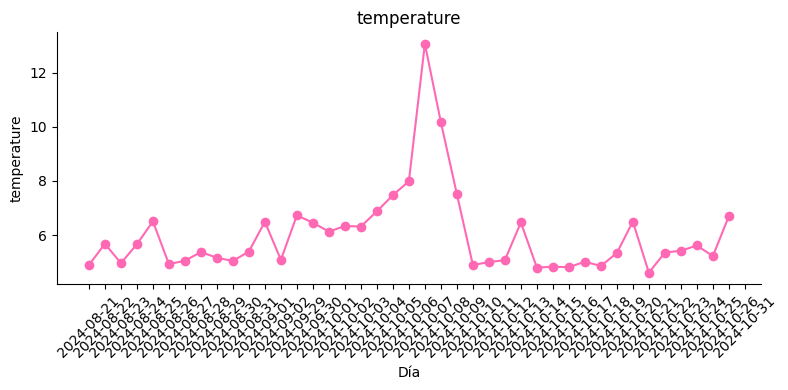

['2024-10-26', '2024-10-13']


In [ ]:
# Variables a graficar
variables = ['compressor', 'open_time', 'door_opens', 'on_time', 'power', 'temperature']
# ID Cooler
cooler_id_target = '8d3260b5f7e49fff02b4743037a52406b19279d9cd0144785f653afe0f4622b8'

# Filtro del Cooler, formato de fecha y día
filtered_coolers = coolers[coolers['cooler_id'] == cooler_id_target].copy()
filtered_coolers['calday'] = pd.to_datetime(filtered_coolers['calday'], format='%Y%m%d')
filtered_coolers['day'] = filtered_coolers['calday'].dt.to_period('d')

# Ciclo para mostrar el gráfico por cada una de las variables
min_days = {}
for var in variables:
    daily_avg = filtered_coolers.groupby('day')[var].mean().reset_index()
    plt.figure(figsize=(8, 4))
    plt.plot(daily_avg['day'].astype(str), daily_avg[var], marker='o', color='hotpink')
    plt.title(var)
    plt.gca().spines[['top', 'right']].set_visible(False)
    plt.xlabel('Día')
    plt.ylabel(var)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    min_value = daily_avg[var].min()
    min_day = daily_avg[daily_avg[var] == min_value]['day'].tolist()
    min_days[var] = set(min_day)

all_days = set().union(*min_days.values())
result_days = []
for day in all_days:
    count = sum([day in min_days[var] for var in variables])
    if count >= 3:
        result_days.append(str(day))
print(result_days)

## Ingenieria de Variables

Para el desarrollo del modelo se cean variables tecnicas que se derivan de los datos de los microcontroladores como variacion de voltaje, eficiencia energetica, y bajas temperaturas

In [ ]:
df['volt_range'] = df['max_voltage'] - df['min_voltage']  # Rango de voltaje
df['energy_per_min'] = df['power'] / (df['open_time'] + 1e-3)  # Energía por minuto abierto
df['temp_power_ratio'] = df['temperature'] / (df['power'] + 1e-3)  # Relación temperatura/consumo
df['door_efficiency'] = df['door_opens'] / (df['on_time'] + 1e-3)  # Aperturas por hora encendido
df['is_high_temp'] = (df['temperature'] > 7).astype(int)  # Etiqueta si la temperatura fue alta
df['is_voltage_unstable'] = (df['volt_range'] > 30).astype(int)  # Etiqueta si hubo inestabilidad

## Balanceo de la base de datos

Debido a la previa visualizacion de lo desbalanceado dentro de la base de datos, se hace una submuestra de los elementos que no tienen fallos para la mejora en el algoritmo de aprendizaje

In [ ]:
positivos = df[df['has_warning'] == 1]
# Minimos para una muestra de negativos
negativos = df[df['has_warning'] == 0].sample(n=min(200000, len(df[df['has_warning'] == 0])), random_state=42)
df_bal = pd.concat([positivos, negativos])

## Preparacion del modelo

Para el entrenamiento se eliminan las variables de IDs y fechas ya que se conocen algunas caracteristicas temporales.

In [ ]:
# Preparación de variables para el modelo
X_train = df_bal.drop(columns=['has_warning', 'cooler_id', 'customer_id', 'calday', 'calmonth', 'month'])
y_train = df_bal['has_warning']

# Imputación de valores faltantes y normalización
imp = SimpleImputer(strategy='median')
# Imputación con la mediana para evitar afectar a la distribución
X_train_imputed = imp.fit_transform(X_train)
# Escalar para poder hacer un entrenamiento balanceado
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)

Se hace una imputacion de datos con la mediana, asi como una normalizacion de los datos con el fin de mejorar el rendimiento del modelo.

##Modelado con XGBoost

Al importar el algoritmo, se elige XGBoost debido al manejo de relaciones no lineales en los datos de los microcontroladores, y buen manejo de la falta de balance en las bases de datos.

In [ ]:
# Se establece reproductibilidad, hace una depreciación hacia codificación de etiquetas
model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
model.fit(X_train_scaled, y_train)

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [15:53:45] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=42, ...)

Se agrupan los datos iniciales obtenidos de los registros de Arca Continental, en donde se hace la transformación de datos

In [ ]:
# Simulación de condiciones de mayo 2025
# Usamos promedios históricos por cooler para representar su estado esperado en mayo 2025
df_mayo = df.groupby('cooler_id').agg({
    'door_opens': 'mean',
    'open_time': 'mean',
    'compressor': 'mean',
    'power': 'mean',
    'on_time': 'mean',
    'min_voltage': 'mean',
    'max_voltage': 'mean',
    'temperature': 'mean',
    'amount': 'mean',
    'day': 'median',
    'volt_range': 'mean',
    'energy_per_min': 'mean',
    'temp_power_ratio': 'mean',
    'door_efficiency': 'mean',
    'is_high_temp': 'mean',
    'is_voltage_unstable': 'mean'
}).reset_index()

cooler_ids = df_mayo['cooler_id']
X_mayo = df_mayo.drop(columns=['cooler_id'])

# Aseguramos que las columnas estén en el mismo orden
X_mayo = X_mayo[X_train.columns]

# Aplicamos las mismas transformaciones aprendidas
X_mayo_imputed = imp.transform(X_mayo)
X_mayo_scaled = scaler.transform(X_mayo_imputed)

## Resultado del modelo

Se simulan las condiciones de mayo 2025 usando promedios históricos por cooler y se aplican las mismas transformaciones que en el entrenamiento.  
Se generan las predicciones de probabilidad y clase para cada cooler.

Para las predicciones se han calculado la probabilidad de falla y predicccion binaria a la base de datos anterior que contiene cada una de las variables de los coolers.

In [ ]:
# Predicciones y calculo de scores
y_scores = model.predict_proba(X_mayo_scaled)[:, 1]
y_preds = (y_scores >= 0.5).astype(int)

# Guardar resultados
df_resultados = pd.DataFrame({
    'cooler_id': cooler_ids,
    'prob_failure': np.round(y_scores, 4),  # Probabilidad con 4 decimales
    'predicted_failure': y_preds  # 1 si se predice que fallará, 0 si no
})

df_resultados.to_csv("predicciones_mayo2025.csv", index=False)
print("Archivo generado: predicciones_mayo2025.csv")

Archivo generado: predicciones_mayo2025.csv


Si bien el desarrollo de XGBoost es un modelo de alta complejidad, y en donde se pudieron implementar otros algoritmos como el de regresion logistica son menos precisas para el analisis de datos.

El modelo actual brinda la prediccion al siguiente mes sobre el riesgo existente de que el usuario reporte su cooler.

Se genera un archivo con la probabilidad de fallo y la predicción binaria para cada cooler, facilitando la toma de decisiones de mantenimiento preventivo.